In [1]:
#importing the libraries we need to use for data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import MinMaxScaler

print("All good")

All good


In [2]:
#load the data set into the data frame(allows us to start exploring for potential data cleanups)
df = pd.read_csv("ai_productivity_dataset_final.csv")

# set display.max_columns to None so we can see all of them
pd.set_option('display.max_columns', None)

# first 5 rows to get a gist of what the data looks like
df.head()

,task_id,client,project_id,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,created_by,updated_at,task_status,workflow_stage,jira_ticket,legacy_ai_flag,content_version
0,T00000,Client_F,P038,mid,Content,report,junior,2,3.0,high,0,hourly,2025-11-20,2025-11-25,10.0,0,7.63,5.14,0.75,True,1,1,2.10,69.93,498.11,346.17,151.94,user_096,2025-11-28,review,finalized,JIRA-49014,true,v1
1,T00001,Client_H,P028,low,Paid Media,release,junior,1,2.0,medium,0,fixed,2026-01-24,2026-01-26,7.0,0,9.52,8.22,0.12,False,1,1,4.48,82.79,847.01,343.18,503.83,user_058,2026-01-26,delivered,client_review,JIRA-84793,false,v1
2,T00002,Client_D,P009,low,Design,dev,junior,3,4.0,medium,0,fixed,2025-09-16,2025-09-23,5.0,1,8.45,6.15,0.37,True,2,0,2.71,76.40,1374.07,365.02,1009.05,user_074,2025-09-17,in_progress,qa,JIRA-42485,true,v2
3,T00003,Client_E,P023,mid,Content,design,mid,3,2.0,low,0,hourly,2025-11-06,2025-11-09,3.0,0,28.35,24.22,0.07,False,4,1,0.00,NaN,2379.11,1514.73,864.38,user_011,2025-11-12,in_progress,briefing,JIRA-53111,false,v1
4,T00004,Client_C,P014,low,Design,article,senior,2,5.0,low,0,fixed,2026-05-02,2026-05-06,7.0,0,5.93,4.44,0.20,True,2,2,0.84,NaN,709.95,335.27,374.68,user_007,2026-05-09,review,execution,JIRA-86006,true,v2


In [3]:
# checking the column names to see what variables we are working with
print("Columns:", df.columns)

# getting general information about the dataset to check for missing values
df.info()

#rows and columns
print("Shape:", df.shape)

Columns: Index(['task_id', 'client', 'project_id', 'client_tier', 'team', 'task_type',
       'seniority', 'task_complexity_score', 'brief_quality_score',
       'deadline_pressure', 'scope_change_flag', 'pricing_model', 'created_at',
       'delivered_at', 'sla_days', 'sla_breach', 'hours_spent',
       'billable_hours', 'ai_usage_pct', 'ai_assisted', 'revisions', 'errors',
       'rework_hours', 'outcome_score', 'revenue', 'cost', 'profit',
       'created_by', 'updated_at', 'task_status', 'workflow_stage',
       'jira_ticket', 'legacy_ai_flag', 'content_version'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3248 entries, 0 to 3247
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   task_id                3248 non-null   str    
 1   client                 3248 non-null   str    
 2   project_id             3248 non-null   str    
 3   client_tier            3248 non-null   str   

In [4]:
#so we don't accidentally change the original dataset
df_clean = df.copy()

In [5]:
#remove columns with no useful information
cols_to_drop = ['task_id', 'client', 'project_id', 'created_by', 'updated_at', 'jira_ticket', 'legacy_ai_flag']
df_clean = df_clean.drop(columns=cols_to_drop)

In [6]:
# check for improperly labeled values
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(), 
      sep='\n\n')

team
Content       803
Media         781
Design        761
SEO           747
seo            29
media          25
content        22
design         19
SEO            18
DESIGN         12
Paid Media      8
Contennt        8
MEDIA           7
Desgn           6
CONTENT         2
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design            456
ad                453
ticket            451
report            447
article           446
dev               435
release           421
article_task       15
ad_task            11
relese             11
ticket_task        11
design_task        10
Ticket              8
Report              8
release_task        8
report_task         7
Design              7
Ad                  6
development         5
creative            5
dev_task            4
repport             4
paid_ad             4
artcle              3
support_ticket      3
Release             3
blog_article        3
DEV             

In [7]:
# set all string values to lowercase and rename those labeled incorrectly
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[col] = df_clean[col].str.lower()

df_clean['team'] = df_clean['team'].replace({
    'seo ': 'seo',
    'contennt': 'content',
    'desgn': 'design',
    'paid media': 'media'
})

df_clean['task_type'] = df_clean['task_type'].replace({
    'article_task': 'task',
    'ad_task': 'ad',
    'relese': 'release',
    'ticket_task': 'ticket',
    'design_task': 'design',
    'release_task': 'release',
    'report_task': 'report',
    'development': 'dev',
    'creative': 'design',
    'dev_task': 'dev',
    'repport': 'report',
    'paid_ad': 'ad',
    'artcle': 'article',
    'support_ticket': 'ticket',
    'blog_article': 'article'
})

In [8]:
# check value counts again to make sure all values were handled properly
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(),
      sep='\n\n')

team
content    835
media      821
design     798
seo        794
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design     478
ad         474
ticket     473
report     466
article    453
dev        446
release    443
task        15
Name: count, dtype: int64

seniority
mid       1296
junior    1190
senior     762
Name: count, dtype: int64

deadline_pressure
medium    1482
low        914
high       852
Name: count, dtype: int64

pricing_model
hourly         1561
fixed          1227
value_based     460
Name: count, dtype: int64

task_status
in_progress    1129
review          866
delivered       769
draft           183
archived        151
blocked         150
Name: count, dtype: int64

workflow_stage
qa               687
client_review    664
finalized        643
briefing         640
execution        614
Name: count, dtype: int64


In [9]:
# drop 15 tasks labeled as "task"
df_clean = df_clean[df_clean['task_type'] != 'task']

In [10]:
#summary of all columns(numerical & categorical);to understand general patterns in the dataa
df_clean.describe(include='all')

,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,task_status,workflow_stage,content_version
count,3233,3233,3233,3233,3233.000000,3164.000000,3233,3233.000000,3233,3233,3196,3197.000000,3233.000000,3233.000000,3151.000000,3089.000000,3233,3233.000000,3233.000000,3162.000000,3100.000000,3233.000000,3233.000000,3233.000000,3233,3233,3233
unique,3,4,7,3,NaN,NaN,3,NaN,3,330,335,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,5,5
top,mid,content,design,mid,NaN,NaN,medium,NaN,hourly,2026-03-27,2026-01-18,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,in_progress,qa,v1
freq,1506,830,478,1294,NaN,NaN,1475,NaN,1555,22,19,NaN,NaN,NaN,NaN,NaN,2548,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1125,682,920
mean,NaN,NaN,NaN,NaN,2.869780,3.181732,NaN,0.137952,NaN,NaN,NaN,5.018142,0.397773,13.055105,8.439149,0.361379,NaN,3.005258,1.014847,2.433680,68.838981,1121.564536,772.210829,349.353707,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,1.196139,1.210987,NaN,0.344903,NaN,NaN,NaN,2.521184,0.489514,11.544270,4.789097,0.199398,NaN,1.803712,1.042311,2.911877,12.624994,843.028776,585.359090,889.807709,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,2.000000,0.000000,0.020000,-1.900000,0.000000,NaN,0.000000,0.000000,0.000000,9.000000,45.000000,77.850000,-8510.549511,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,2.000000,NaN,0.000000,NaN,NaN,NaN,3.000000,0.000000,7.930000,5.085000,0.200000,NaN,2.000000,0.000000,1.110000,60.867500,647.030000,440.460000,-2.860000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.000000,3.000000,NaN,0.000000,NaN,NaN,NaN,5.000000,0.000000,11.120000,7.540000,0.340000,NaN,3.000000,1.000000,1.810000,69.350000,967.570000,649.210000,254.820000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,4.000000,NaN,0.000000,NaN,NaN,NaN,7.000000,1.000000,15.360000,10.695000,0.500000,NaN,4.000000,2.000000,2.940000,77.542500,1364.600000,943.850000,590.580000,NaN,NaN,NaN


# Missing values

Because brief_quality_score, sla_days, billable_hours, ai_usage_pct, rework_hours, and outcome_score are all numeric features we can easily impute them using iterative imputation. We can assume missing values depend on multiple features, therefore this approach is justifiable. Unfortunately, delivered_at can't be imputed, thus these rows will be removed.


client_tier                0
team                       0
task_type                  0
seniority                  0
task_complexity_score      0
brief_quality_score       69
deadline_pressure          0
scope_change_flag          0
pricing_model              0
created_at                 0
delivered_at              37
sla_days                  36
sla_breach                 0
hours_spent                0
billable_hours            82
ai_usage_pct             144
ai_assisted                0
revisions                  0
errors                     0
rework_hours              71
outcome_score            133
revenue                    0
cost                       0
profit                     0
task_status                0
workflow_stage             0
content_version            0
dtype: int64


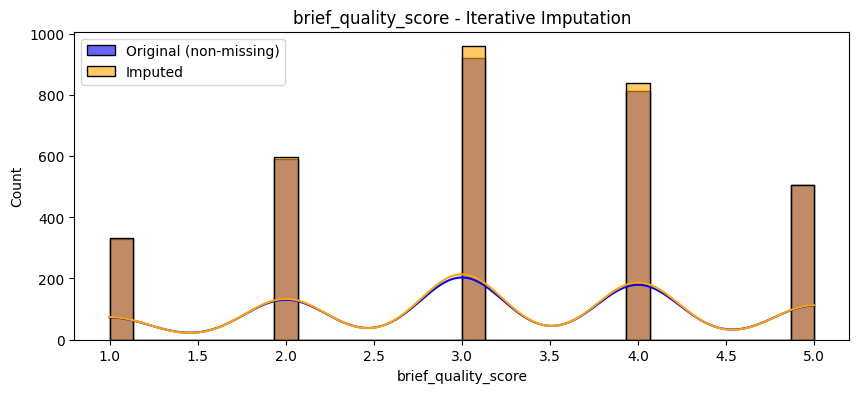

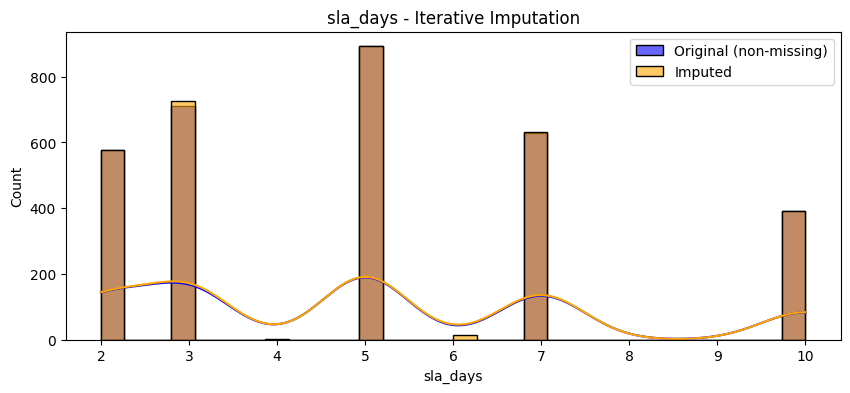

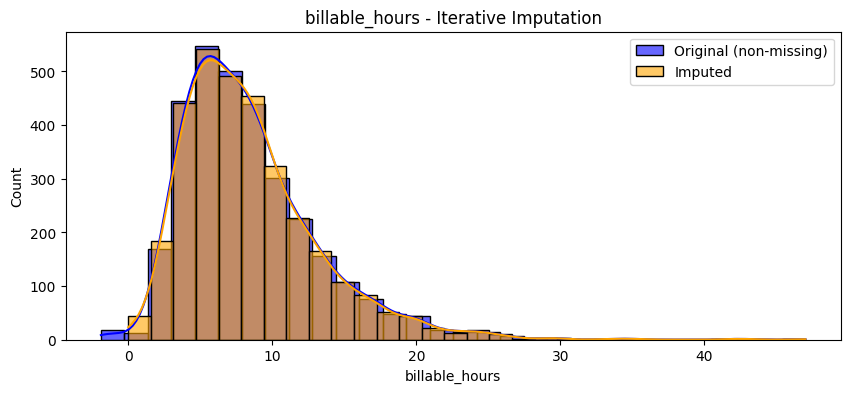

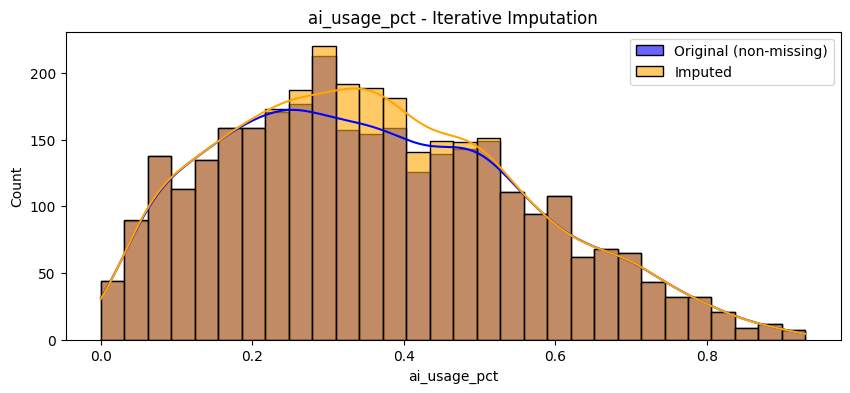

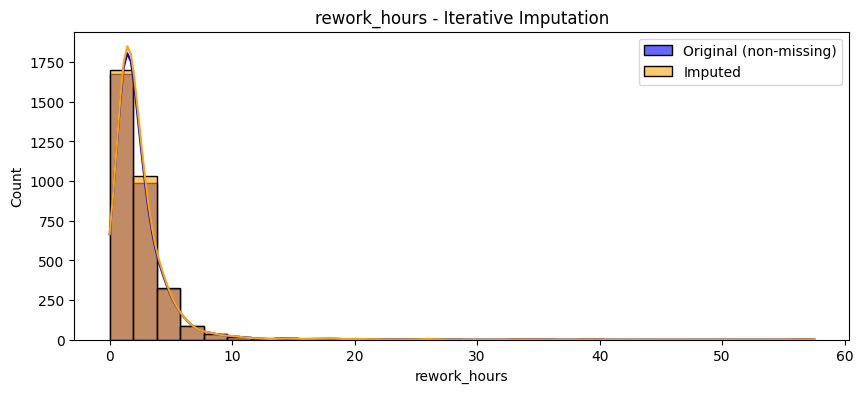

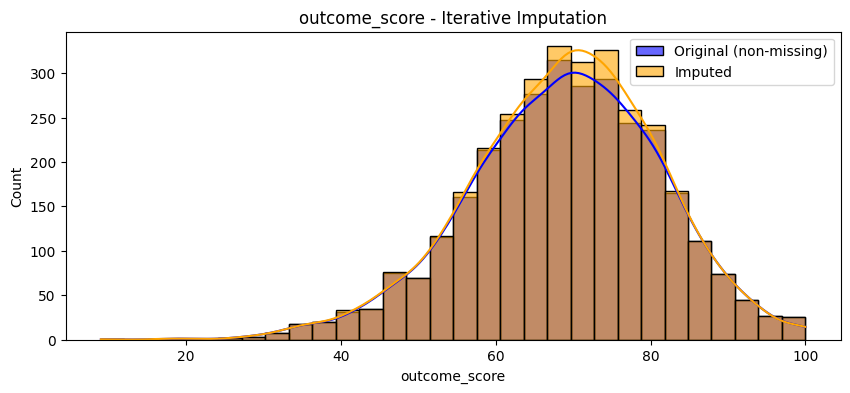

In [11]:
print(df_clean.isnull().sum())

# iterative imputation
df_numerical = df_clean.select_dtypes(include=['number'])

iter_imp = IterativeImputer(random_state=42)
df_iter = pd.DataFrame(iter_imp.fit_transform(df_numerical), columns=df_numerical.columns)

# round brief_quality_score and sla_days such that they are integers
df_iter['brief_quality_score'] = df_iter['brief_quality_score'].round()
df_iter['sla_days'] = df_iter['sla_days'].round()

# remove negative billable_hours
df_iter['billable_hours'] = df_iter['billable_hours'].clip(lower=0)

# plot the orignal vs. imputed distributions of numerical features
def plot_imputation_comparison(original, imputed, title):
    plt.figure(figsize=(10, 4))
    sns.histplot(original.dropna(), kde=True, color='blue', label='Original (non-missing)', bins=30, alpha=0.6)
    sns.histplot(imputed, kde=True, color='orange', label='Imputed', bins=30, alpha=0.6)
    plt.title(title)
    plt.legend()
    plt.show()

for col in df_numerical.columns:
    if df_numerical[col].isnull().any():
        plot_imputation_comparison(df_numerical[col], df_iter[col], f"{col} - Iterative Imputation")

# merge the imputed data back into the original df
df_clean[df_numerical.columns] = df_iter

# drop rows with missing delivered_at values
df_clean = df_clean.dropna()

In [12]:
#checking final shape after cleaning
print("Final shape:", df_clean.shape)
#make sure there arnet missing values left
print(df_clean.isnull().sum())
#confirm no remaining duplicate rows
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Final shape: (3181, 27)
client_tier              0
team                     0
task_type                0
seniority                0
task_complexity_score    0
brief_quality_score      0
deadline_pressure        0
scope_change_flag        0
pricing_model            0
created_at               0
delivered_at             0
sla_days                 0
sla_breach               0
hours_spent              0
billable_hours           0
ai_usage_pct             0
ai_assisted              0
revisions                0
errors                   0
rework_hours             0
outcome_score            0
revenue                  0
cost                     0
profit                   0
task_status              0
workflow_stage           0
content_version          0
dtype: int64
Duplicate rows after cleaning: 0


# EDA


## Heatmap

The heatmap reveals interesting relationships: negative relationship between ai_usage_pct and sla_breach, billable_hours, and cost.

Other interesting relationships include: negative correlations between outcome_score and task_complexity_score, revisions, errors and rework_hours.

No strong trends emerge regarding revenue, cost or profit.


<Axes: >

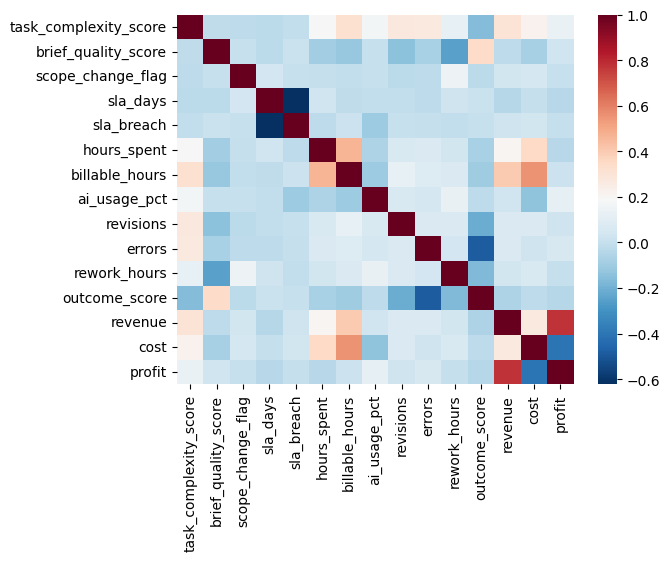

In [13]:
corr = df_numerical.corr()

sns.heatmap(corr, cmap = 'RdBu_r')

## Regression


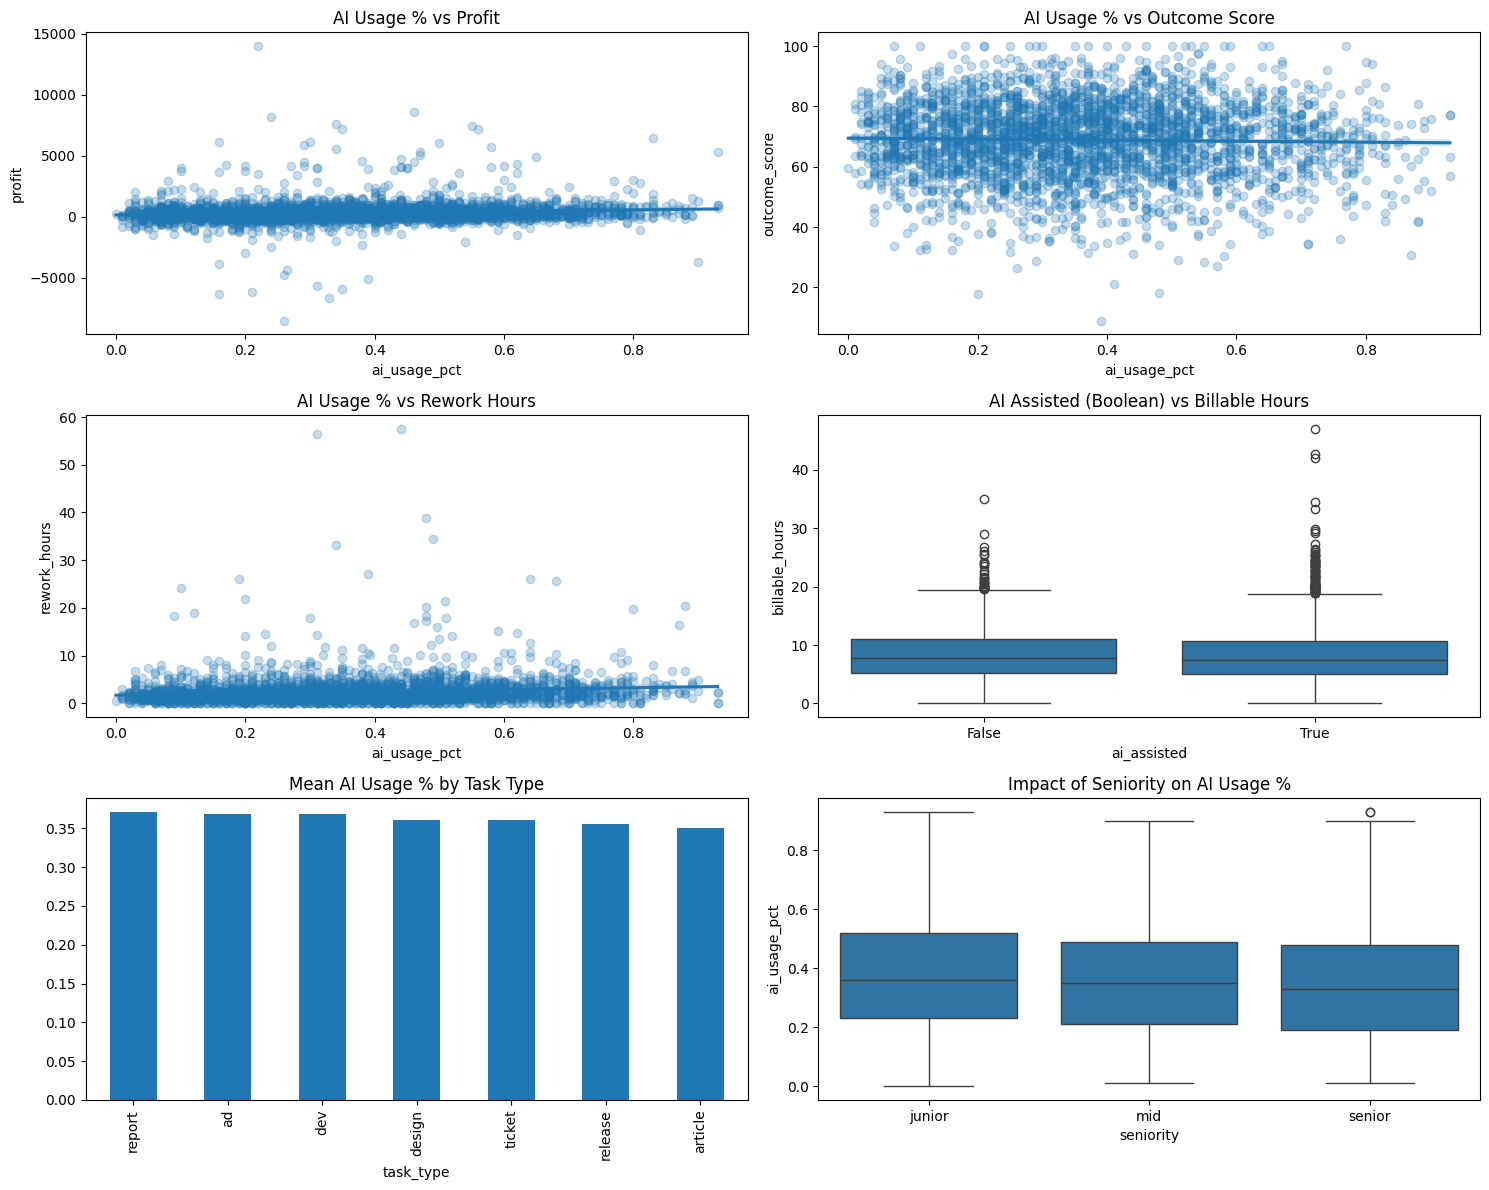

In [14]:
plt.figure(figsize=(15, 12))

plt.subplot(3, 2, 1)
sns.regplot(data=df_clean, x='ai_usage_pct', y='profit', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Profit')

plt.subplot(3, 2, 2)
sns.regplot(data=df_clean, x='ai_usage_pct', y='outcome_score', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Outcome Score')

plt.subplot(3, 2, 3)
sns.regplot(data=df_clean, x='ai_usage_pct', y='rework_hours', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Rework Hours')

plt.subplot(3, 2, 4)
sns.boxplot(data=df_clean, x='ai_assisted', y='billable_hours')
plt.title('AI Assisted (Boolean) vs Billable Hours')

plt.subplot(3, 2, 5)
df_clean.groupby('task_type')['ai_usage_pct'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Mean AI Usage % by Task Type')

plt.subplot(3, 2, 6)
sns.boxplot(data=df_clean, x='seniority', y='ai_usage_pct', order=['junior', 'mid', 'senior'])
plt.title('Impact of Seniority on AI Usage %')

plt.tight_layout()

# Analysis


### 1. Where is value created?

Identify tasks where AI produces a measurable and positive impact.


In [15]:
# summary table comparing the mean of efficiency metrics given AI vs Non-AI per task
metrics = ['profit', 'outcome_score', 'hours_spent']
impact_df = df_clean.groupby(['task_type', 'ai_assisted'])[metrics].mean().unstack()

# individual lift % for each metric
impact_df['profit_lift'] = (impact_df['profit'][True] - impact_df['profit'][False]) / impact_df['profit'][False]
impact_df['quality_lift'] = (impact_df['outcome_score'][True] - impact_df['outcome_score'][False]) / impact_df['outcome_score'][False]
impact_df['time_savings'] = (impact_df['hours_spent'][False] - impact_df['hours_spent'][True]) / df_clean['hours_spent'].mean()

print(impact_df[['profit_lift', 'quality_lift', 'time_savings']])

            profit_lift quality_lift time_savings
ai_assisted                                      
task_type                                        
ad            -0.432993    -0.014357     0.008633
article        0.098444    -0.004953    -0.067125
design         0.303485     0.008172     0.132090
dev           -0.129568    -0.014363     0.000717
release       -0.141557     0.033882     0.228605
report         0.110661    -0.020783    -0.097337
ticket        -0.255024    -0.000878     0.025254


Text(0, 0.5, 'Normalized Value Score')

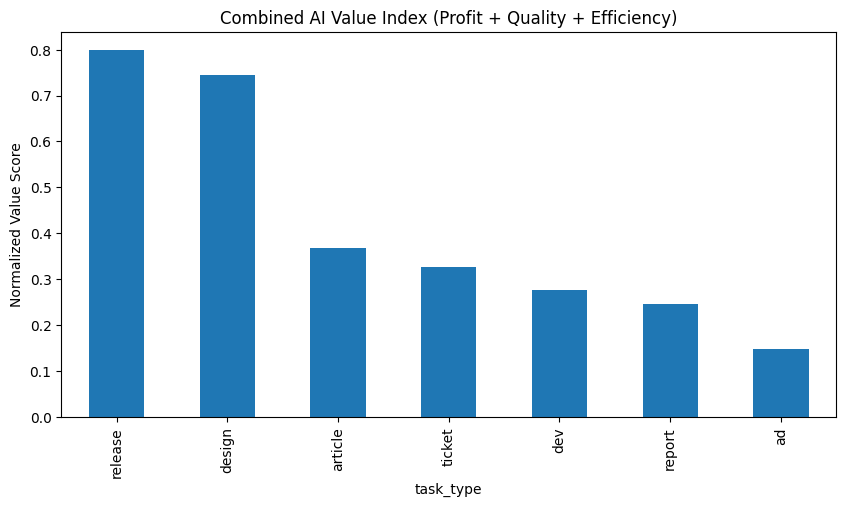

In [16]:
lift_cols = ['profit_lift', 'quality_lift', 'time_savings']
lifts = impact_df[lift_cols]

# normalize all lifts to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_lifts = pd.DataFrame(
    scaler.fit_transform(lifts), 
    index=lifts.index, 
    columns=lift_cols
)

# combined (mean) AI value score
impact_df['AI_Value_Index'] = normalized_lifts.mean(axis=1)

impact_df['AI_Value_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Value Index (Profit + Quality + Efficiency)')
plt.ylabel('Normalized Value Score')

### 2. Where are losses incurred?

Track losses: rework, declining quality, hidden costs


In [17]:
#hidden cost = hours spent but not billed
df_clean['extra_hours'] = df_clean['hours_spent'] - df_clean['billable_hours']

In [18]:
#summary table comparing mean loss metrics for AI vs Non-AI per task
loss_metrics = ['rework_hours', 'extra_hours', 'outcome_score']
loss_df = df_clean.groupby(['task_type', 'ai_assisted'])[loss_metrics].mean().unstack()

#individual loss measures
loss_df['rework_increase'] = (loss_df['rework_hours'][True] - loss_df['rework_hours'][False]) / loss_df['rework_hours'][False]
loss_df['extra_hours_increase'] = (loss_df['extra_hours'][True] - loss_df['extra_hours'][False]) / loss_df['extra_hours'][False]
loss_df['quality_decline'] = (loss_df['outcome_score'][False] - loss_df['outcome_score'][True]) / loss_df['outcome_score'][False]

print(loss_df[['rework_increase', 'extra_hours_increase', 'quality_decline']])

            rework_increase extra_hours_increase quality_decline
ai_assisted                                                     
task_type                                                       
ad                -0.168066            -0.046546        0.014357
article            0.056785             0.047902        0.004953
design            -0.078914            -0.133709       -0.008172
dev                0.033355             0.292726        0.014363
release           -0.123196            -0.377748       -0.033882
report             0.244262             0.272948        0.020783
ticket            -0.003865             0.134572        0.000878


In [19]:
loss_cols = ['rework_increase', 'extra_hours_increase', 'quality_decline']
losses = loss_df[loss_cols].copy()

In [20]:
#cleans up inf values before scaling because percentages won't calculate properly if the demoninator is 0
losses = losses.replace([np.inf, -np.inf], np.nan).fillna(0)

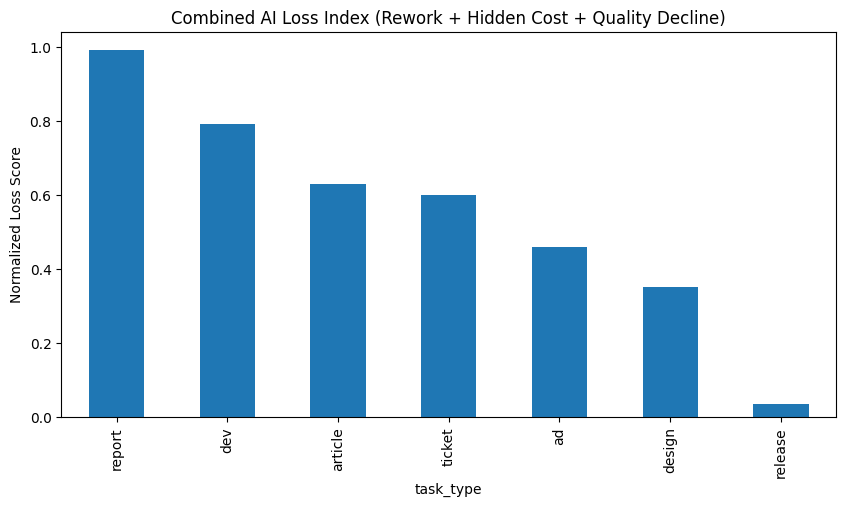

In [21]:
#normalize all loss metrics to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_losses = pd.DataFrame(
    scaler.fit_transform(losses),
    index=losses.index,
    columns=loss_cols
)

#combined mean AI loss score
loss_df['AI_Loss_Index'] = normalized_losses.mean(axis=1)

loss_df['AI_Loss_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Loss Index (Rework + Hidden Cost + Quality Decline)')
plt.ylabel('Normalized Loss Score')
plt.show()

Losses are highest in report and development tasks where AI seems to generate more rework and hidden costs. <br>
Tasks like release and design have much lower losses which suggests that AI is more effective there.


ai_bin
Medium    1447
Low       1339
High       395
Name: count, dtype: int64
count    3181.000000
mean        0.362029
std         0.195363
min         0.000000
25%         0.210000
50%         0.350000
75%         0.500000
max         0.930000
Name: ai_usage_pct, dtype: float64


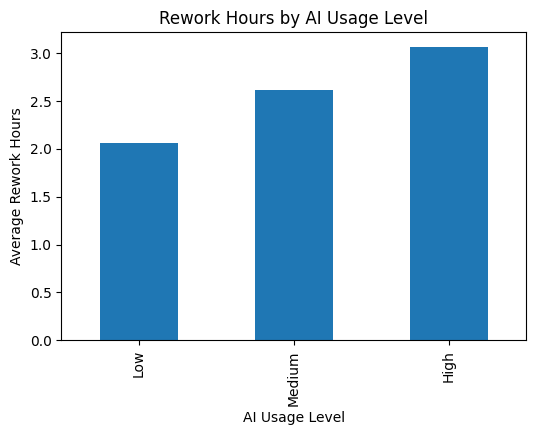

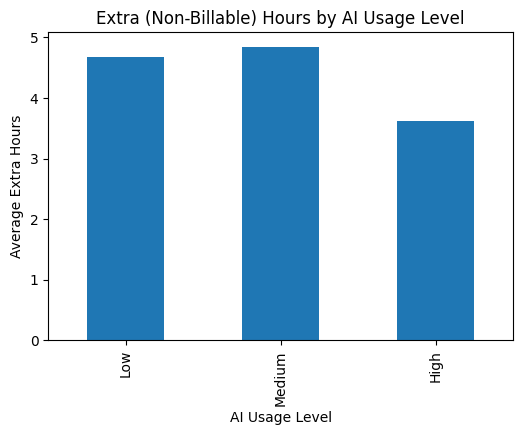

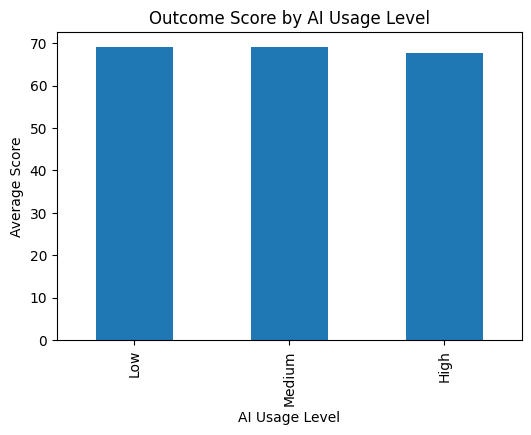

In [22]:
#creates bins to view levels of AI usage
df_clean['ai_bin'] = pd.cut(
    df_clean['ai_usage_pct'],
    bins=[0, 0.3, 0.6, 1],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

#checking num of observations
print(df_clean['ai_bin'].value_counts())
print(df_clean['ai_usage_pct'].describe())

#rework by AI usage level
df_clean.groupby('ai_bin')['rework_hours'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Rework Hours by AI Usage Level')
plt.ylabel('Average Rework Hours')
plt.xlabel('AI Usage Level')
plt.show()

#extra (non-billable) hours by AI usage level
df_clean.groupby('ai_bin')['extra_hours'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Extra (Non-Billable) Hours by AI Usage Level')
plt.ylabel('Average Extra Hours')
plt.xlabel('AI Usage Level')
plt.show()

#outcome score by AI usage level
df_clean.groupby('ai_bin')['outcome_score'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Outcome Score by AI Usage Level')
plt.ylabel('Average Score')
plt.xlabel('AI Usage Level')
plt.show()

Rework increases as AI usage goes up showing that higher AI use leads to more errors that need fixing.<br>
Extra hours are highest at medium AI usage and drop at high levels. This shows hidden costs are persistent at all ai usage levels.<br>
Quality stays roughly stable at low and medium AI usage but drops slightly at high levels. This suggests that a lot of AI use may start to hurt output quality.


### 3. AI -> quality of just speed?

Distinguish the two effects in the data


In [23]:
#compare speed vs quality for AI and for non-AI
sq_metrics = ['hours_spent', 'outcome_score', 'rework_hours']
sq_df = df_clean.groupby('ai_assisted')[sq_metrics].mean()
print(sq_df)

#hours_spent is lower -> faster
#outcome_score is higher -> better quality
#rework_hours is lower -> less rework needed

             hours_spent  outcome_score  rework_hours
ai_assisted                                          
False          13.410804      69.011363      2.467806
True           12.994673      68.835313      2.426564


In [35]:

#calculating percent change for time, quality, and rework between AI-assisted and non-AI-assisted tasks
#how much did this change when we used AI instead of not using AI?
#change = (AI value - Non-AI value) / Non-AI value
sq_change = {
    'time_change': (sq_df.loc[True, 'hours_spent'] - sq_df.loc[False, 'hours_spent']) / sq_df.loc[False, 'hours_spent'],
    'quality_change': (sq_df.loc[True, 'outcome_score'] - sq_df.loc[False, 'outcome_score']) / sq_df.loc[False, 'outcome_score'],
    'rework_change': (sq_df.loc[True, 'rework_hours'] - sq_df.loc[False, 'rework_hours']) / sq_df.loc[False, 'rework_hours']
}

sq_change = pd.DataFrame(sq_change, index=['AI vs Non-AI'])

print(sq_change)
print(sq_df)


              time_change  quality_change  rework_change
AI vs Non-AI     -0.03103       -0.002551      -0.016712
             hours_spent  outcome_score  rework_hours
ai_assisted                                          
False          13.410804      69.011363      2.467806
True           12.994673      68.835313      2.426564


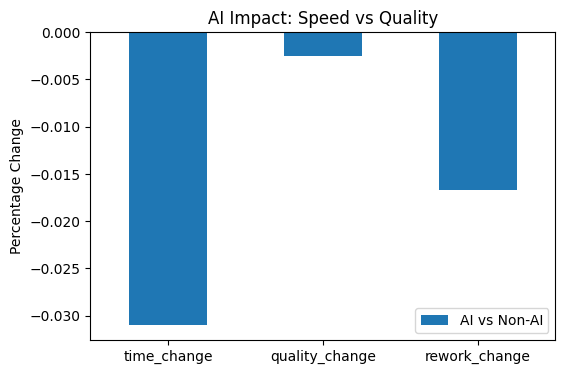

In [34]:
#plots the values
sq_change.T.plot(kind='bar', figsize=(6,4))
plt.title('AI Impact: Speed vs Quality')
plt.ylabel('Percentage Change')
plt.xticks(rotation=0)
plt.show()


#positive = higher with AI
#negative = lower with AI

#time_change negative -> AI is faster
#quality_change negative -> AI lowers quality
#rework_change negative -> AI reduces rework

AI improves efficiency by reducing time and rework. However, this comes with a small drop in output quality.


### 4. When does it become negative?

Find the critical threshold beyond which AI harms the margin.


In [26]:
#group data by ai usage level and calculate mean profit, rework hours, and extra hours for each bin
threshold_df = df_clean.groupby('ai_bin')[['profit', 'rework_hours', 'extra_hours']].mean()
print(threshold_df)

            profit  rework_hours  extra_hours
ai_bin                                       
Low     249.969499      2.060306     4.672648
Medium  401.968450      2.610608     4.842920
High    489.082480      3.064607     3.615678


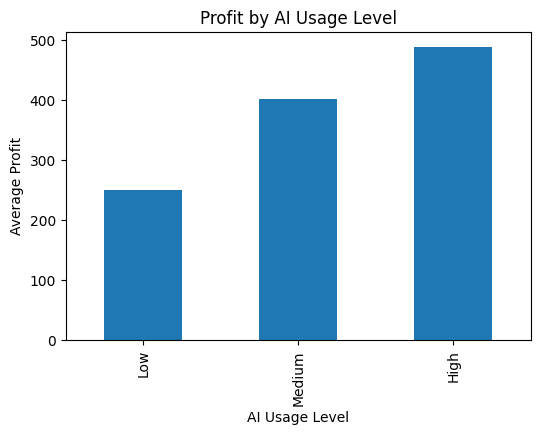

In [27]:
#plot profit by ai usage level
threshold_df['profit'].plot(kind='bar', figsize=(6,4))

plt.title('Profit by AI Usage Level')
plt.ylabel('Average Profit')
plt.xlabel('AI Usage Level')

plt.show()

Higher AI usage yields more profit


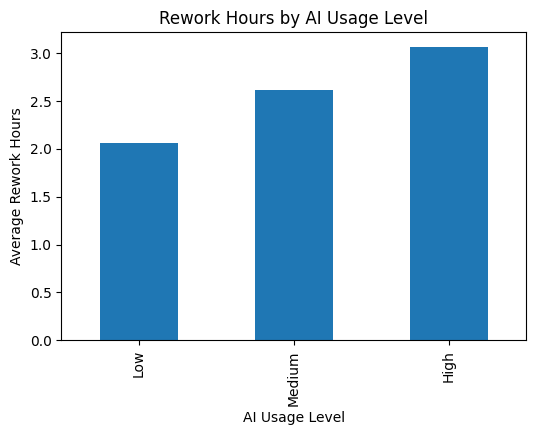

In [28]:
#plot rework hours by ai usage level  
threshold_df['rework_hours'].plot(kind='bar', figsize=(6,4))

plt.title('Rework Hours by AI Usage Level')
plt.ylabel('Average Rework Hours')
plt.xlabel('AI Usage Level')

plt.show()

Rework hours increase as AI usage increases meaning higher AI use leads to more errors. <br>
Using some AI can reduce rework (what we saw in question 2 comparing all AI tasks vs non-AI tasks), but relying on it too much actually increases errors.


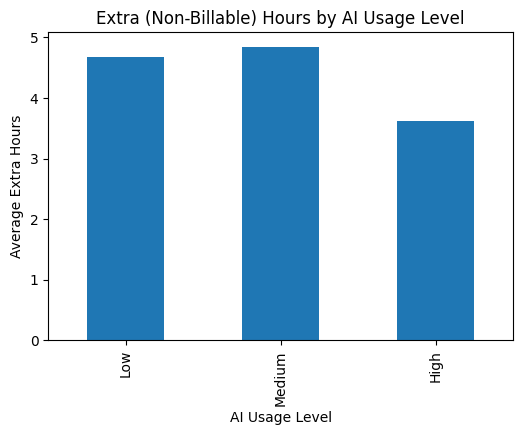

In [30]:
#plot extra hours by ai usage level (hidden cost)
threshold_df['extra_hours'].plot(kind='bar', figsize=(6,4))

plt.title('Extra (Non-Billable) Hours by AI Usage Level')
plt.ylabel('Average Extra Hours')
plt.xlabel('AI Usage Level')

plt.show()


Extra (non-billable) hours are highest at medium AI usage and decrease at high levels. Medium AI use may create more hidden costs than very high use.


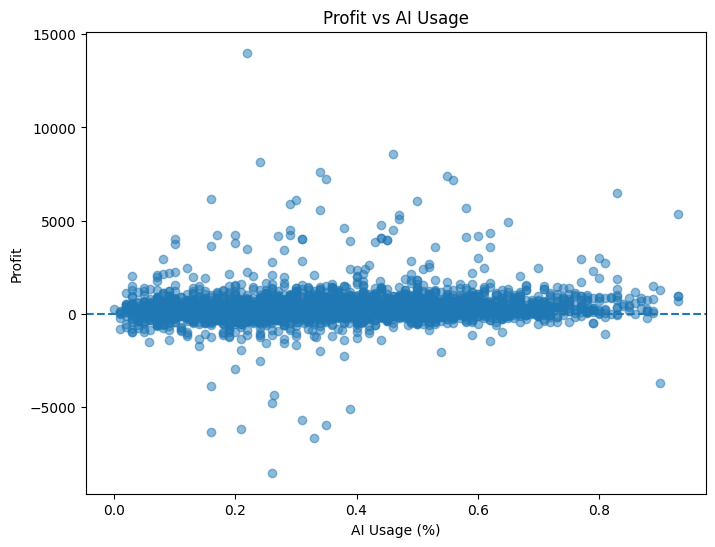

In [37]:
#scatter plot for proft vs AI usage percentage to see if there is a clear relationship or threshold where profit starts to decline
plt.figure(figsize=(8,6))
plt.scatter(df_clean['ai_usage_pct'], df_clean['profit'], alpha=0.5)

plt.xlabel('AI Usage (%)')
plt.ylabel('Profit')
plt.title('Profit vs AI Usage')

#horizontal line at 0 to show break-even point
plt.axhline(y=0, linestyle='--')

plt.show()

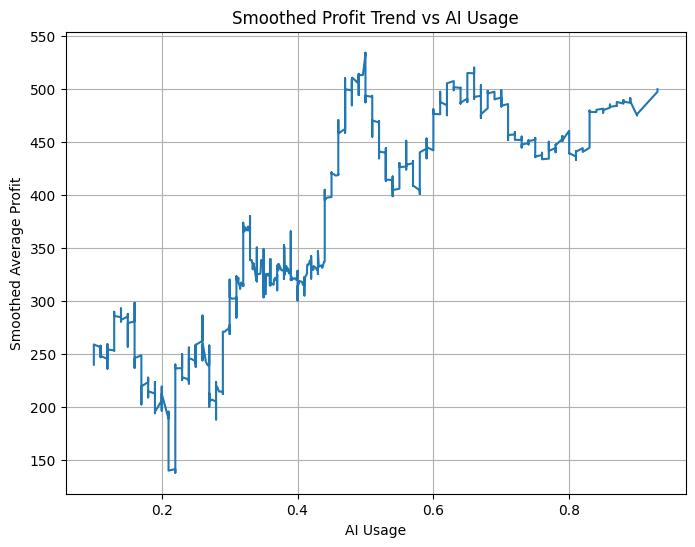

In [38]:
#sort data by AI usage so the trend line follows AI usage from low to high
df_sorted = df_clean.sort_values('ai_usage_pct')

rolling_profit = df_sorted['profit'].rolling(window=300).mean()

#plot the smoother profit trend
plt.figure(figsize=(8,6))
plt.plot(df_sorted['ai_usage_pct'], rolling_profit)

plt.xlabel('AI Usage')
plt.ylabel('Average Profit')
plt.title('Profit Trend vs AI Usage')
plt.grid(True)
plt.show()

In [39]:
#compare profit, rework, and hidden costs across AI usage levels
threshold_df = df_clean.groupby('ai_bin')[['profit', 'rework_hours', 'extra_hours']].mean()
print(threshold_df)

            profit  rework_hours  extra_hours
ai_bin                                       
Low     249.969499      2.060306     4.672648
Medium  401.968450      2.610608     4.842920
High    489.082480      3.064607     3.615678


ai_bin
Low       916.997196
Medium    888.004009
High      778.071581
Name: profit, dtype: float64


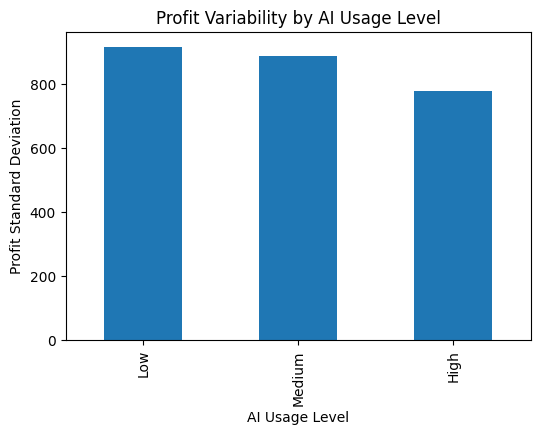

In [40]:
#check whether higher AI usage also makes profit more unstable
profit_risk = df_clean.groupby('ai_bin')['profit'].std()

print(profit_risk)

profit_risk.plot(kind='bar', figsize=(6,4))
plt.title('Profit Variability by AI Usage Level')
plt.ylabel('Profit Standard Deviation')
plt.xlabel('AI Usage Level')
plt.show()

In [41]:
df_clean['ai_usage_pct'].quantile([0.6, 0.7])

0.6    0.40
0.7    0.46
Name: ai_usage_pct, dtype: float64

The data suggests a threshold around 40-45% AI usage. Beyond which increased AI use typically causes more rework even though profit continues to rise.

While higher AI usage increases profit and consistency, it also leads to more rework. This suggests that efficiency gains may come with hidden operational costs.


Overall, with increased AI usage:
* Profit rises
* Stability rises
* Hidden cost rises

1. Why it happens (Why does AI increase profit but also increase rework)?
* AI speeds up initial work, but since it is sped up, small errors are introduced that require fixing later
2. When it happens (Threshold)?
* The trade-offs start appearing at moderate AI usage (around 40-45%) where rework begins to increase.
3. For whom it happens (Who is affected most)?
* The negative effects of AI are strongest in tasks like reports and development.